# Previsão do resultado de partidas da Premier League

**Disciplina:** Machine Learning | **Curso:** Engenharia de Software | **Faculdade:** UniSATC

**Equipe:** Thiago Dallo, Vinicius Fabris e Murilo Cambruzzi

## Problema

Prever, antes de a bola rolar, se uma partida da Premier League termina em vitória do mandante, empate ou vitória do visitante (classificação) e por quantos gols o mandante vence ou perde (regressão, alvo `saldo_gols`).

Técnicas pedidas e usadas: Árvore de Decisão, Ensembles (Random Forest e XGBoost), SVM e K-Means. A Regressão Logística entra como modelo-base interpretável.

## Como o trabalho está organizado

1. Dados e variáveis (Elo, forma recente, contexto da temporada)
2. Divisão temporal e K-Means de estilo de jogo
3. Treino com busca de hiperparâmetros por validação temporal
4. Teste na temporada 2025/26, que nenhum modelo viu
5. Comparação com baselines e com as odds das casas de apostas, usadas só como régua de dificuldade

Para rodar no Colab, execute a primeira célula: ela baixa o repositório com os dados.

In [1]:
import os
import subprocess
import sys

if not os.path.isdir("data"):
    subprocess.run(["git", "clone", "https://github.com/thiagodallo/machine-learning-previsao-futebol"], check=True)
    os.chdir("machine-learning-previsao-futebol")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)

In [2]:
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score, f1_score, log_loss, mean_absolute_error, mean_squared_error,
    r2_score, recall_score, roc_auc_score, silhouette_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import roc_curve

PASTA_PROJETO = Path.cwd()
PASTA_DADOS = PASTA_PROJETO / "data"
PASTA_FIGURAS = PASTA_PROJETO / "figs"

SEMENTE = 42


CLASSES = ["A", "D", "H"]


CODIGO_CLASSE = {classe: indice for indice, classe in enumerate(CLASSES)}


TEMPORADAS_AGRUPAMENTO = ["2014/15", "2015/16", "2016/17", "2017/18"]


TEMPORADAS_VALIDACAO = [
    "2018/19", "2019/20", "2020/21", "2021/22", "2022/23", "2023/24", "2024/25",
]


TEMPORADA_TESTE = "2025/26"


TEMPORADA_FUTURA = "2026/27"


COLUNAS_BRUTAS = [
    "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR",
    "HS", "AS", "HST", "AST", "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR",
    "B365H", "B365D", "B365A",
]


ESTATISTICAS_JOGO = [
    "gols_pro", "gols_contra", "chutes_pro", "chutes_contra",
    "no_alvo_pro", "no_alvo_contra", "escanteios_pro", "escanteios_contra",
    "faltas_pro", "amarelos_pro", "vermelhos_pro", "pontos",
]


COLUNAS_ESTILO = [coluna for coluna in ESTATISTICAS_JOGO if coluna != "pontos"]


JANELA_FORMA = 5


JANELA_ESTILO = 10


MINIMO_JOGOS_ESTILO = 5


ELO_INICIAL = 1500.0


ELO_PROMOVIDO = 1450.0


ELO_K = 20.0


ELO_VANTAGEM_CASA = 65.0


ELO_REGRESSAO_TEMPORADA = 0.25

## 1. Dados

Fonte: [football-data.co.uk](https://www.football-data.co.uk/englandm.php), arquivos `E0` de cada temporada. São 12 temporadas completas (2014/15 a 2025/26, 4.560 jogos) com resultado, chutes, chutes no alvo, escanteios, faltas e cartões por partida. A temporada 2026/27 está incompleta (100 jogos) e entra só como checagem extra no fim.

O Brasileirão foi avaliado e descartado: a melhor base aberta encontrada tem estatísticas de jogo em cerca de 750 partidas, em três temporadas e com falhas, o que não sustenta uma divisão temporal nem o K-Means de estilo.

### Variáveis (todas calculadas só com jogos anteriores)

- **Elo:** nota de força de cada time, atualizada após cada jogo (K = 20, vantagem de mandante de 65 pontos, peso pelo saldo de gols)
- **Forma:** média dos últimos 5 jogos de cada time em 12 estatísticas (gols, chutes, escanteios, faltas, cartões, pontos)
- **Contexto:** pontos por jogo na temporada, jogos disputados e dias de descanso

In [3]:
def carregar_partidas():
    quadros = []
    for caminho in sorted(PASTA_DADOS.glob("E0_*.csv")):
        quadro = pd.read_csv(
            caminho, encoding="utf-8-sig", usecols=lambda coluna: coluna in COLUNAS_BRUTAS
        ).dropna(subset=["HomeTeam"])
        codigo = caminho.stem.split("_")[1]
        quadro["temporada"] = f"20{codigo[:2]}/{codigo[2:]}"
        quadros.append(quadro)
    partidas = pd.concat(quadros, ignore_index=True)
    partidas["data"] = pd.to_datetime(partidas["Date"], dayfirst=True, format="mixed")
    partidas = partidas.sort_values(["data", "HomeTeam"], kind="stable").reset_index(drop=True)
    return partidas.rename(columns={"HomeTeam": "casa", "AwayTeam": "fora", "FTR": "resultado"})


def pontos_do_resultado(resultado, e_mandante):
    if resultado == "D":
        return 1
    return 3 if (resultado == "H") == e_mandante else 0


def montar_formato_longo(partidas):
    visoes = []
    for e_mandante in (True, False):
        lado, outro = ("H", "A") if e_mandante else ("A", "H")
        visao = pd.DataFrame({
            "id_partida": partidas.index,
            "time": partidas["casa" if e_mandante else "fora"],
            "data": partidas["data"],
            "temporada": partidas["temporada"],
            "mandante": e_mandante,
            "gols_pro": partidas[f"FT{lado}G"],
            "gols_contra": partidas[f"FT{outro}G"],
            "chutes_pro": partidas[f"{lado}S"],
            "chutes_contra": partidas[f"{outro}S"],
            "no_alvo_pro": partidas[f"{lado}ST"],
            "no_alvo_contra": partidas[f"{outro}ST"],
            "escanteios_pro": partidas[f"{lado}C"],
            "escanteios_contra": partidas[f"{outro}C"],
            "faltas_pro": partidas[f"{lado}F"],
            "amarelos_pro": partidas[f"{lado}Y"],
            "vermelhos_pro": partidas[f"{lado}R"],
            "pontos": [pontos_do_resultado(r, e_mandante) for r in partidas["resultado"]],
        })
        visoes.append(visao)
    longo = pd.concat(visoes, ignore_index=True)
    return longo.sort_values(["time", "data"], kind="stable").reset_index(drop=True)


def media_movel_anterior(longo, colunas, janela, minimo):
    anterior = longo.groupby("time")[colunas].shift(1)
    anterior["time"] = longo["time"]
    medias = anterior.groupby("time")[colunas].rolling(janela, min_periods=minimo).mean()
    return medias.reset_index(level=0, drop=True).sort_index()


def acrescentar_contexto_de_temporada(longo):
    por_time_temporada = longo.groupby(["time", "temporada"])
    pontos_antes = por_time_temporada["pontos"].cumsum() - longo["pontos"]
    jogos_antes = por_time_temporada.cumcount()
    longo["pontos_por_jogo_temporada"] = (pontos_antes / jogos_antes.replace(0, np.nan))
    longo["jogos_na_temporada"] = jogos_antes
    longo["descanso_dias"] = longo.groupby("time")["data"].diff().dt.days.clip(upper=30)
    return longo


def calcular_variaveis_por_time(partidas):
    longo = montar_formato_longo(partidas)
    forma = media_movel_anterior(longo, ESTATISTICAS_JOGO, JANELA_FORMA, 1).add_prefix("forma_")
    estilo = media_movel_anterior(
        longo, COLUNAS_ESTILO, JANELA_ESTILO, MINIMO_JOGOS_ESTILO
    ).add_prefix("estilo_")
    longo = acrescentar_contexto_de_temporada(longo)
    return pd.concat([longo, forma, estilo], axis=1)


def fator_de_gols(diferenca):
    if diferenca <= 1:
        return 1.0
    if diferenca == 2:
        return 1.5
    return (11 + diferenca) / 8


def calcular_elo(partidas):
    notas = {}
    temporada_atual = None
    elo_casa, elo_fora = [], []
    for linha in partidas.itertuples():
        if linha.temporada != temporada_atual:
            temporada_atual = linha.temporada
            for time in notas:
                notas[time] += ELO_REGRESSAO_TEMPORADA * (ELO_INICIAL - notas[time])
        nota_casa = notas.setdefault(linha.casa, ELO_PROMOVIDO)
        nota_fora = notas.setdefault(linha.fora, ELO_PROMOVIDO)
        elo_casa.append(nota_casa)
        elo_fora.append(nota_fora)
        esperado = 1 / (1 + 10 ** (-(nota_casa + ELO_VANTAGEM_CASA - nota_fora) / 400))
        real = {"H": 1.0, "D": 0.5, "A": 0.0}[linha.resultado]
        ajuste = ELO_K * fator_de_gols(abs(linha.FTHG - linha.FTAG)) * (real - esperado)
        notas[linha.casa] = nota_casa + ajuste
        notas[linha.fora] = nota_fora - ajuste
    return np.array(elo_casa), np.array(elo_fora)


def montar_tabela_de_partidas():
    partidas = carregar_partidas()
    variaveis = calcular_variaveis_por_time(partidas)
    colunas_variaveis = [
        coluna for coluna in variaveis.columns
        if coluna.startswith(("forma_", "estilo_"))
        or coluna in ("pontos_por_jogo_temporada", "jogos_na_temporada", "descanso_dias")
    ]
    casa = variaveis[variaveis["mandante"]].set_index("id_partida")[colunas_variaveis].add_prefix("casa_")
    fora = variaveis[~variaveis["mandante"]].set_index("id_partida")[colunas_variaveis].add_prefix("fora_")
    tabela = partidas.join(casa).join(fora)
    tabela["elo_casa"], tabela["elo_fora"] = calcular_elo(partidas)
    tabela["elo_diferenca"] = tabela["elo_casa"] - tabela["elo_fora"]
    tabela["saldo_gols"] = tabela["FTHG"] - tabela["FTAG"]
    return tabela

In [4]:
tabela = montar_tabela_de_partidas()
print(tabela.shape)
tabela[["data", "casa", "fora", "resultado", "elo_casa", "elo_fora", "casa_forma_gols_pro", "fora_forma_gols_pro"]].tail()

(4660, 79)


,data,casa,fora,resultado,elo_casa,elo_fora,casa_forma_gols_pro,fora_forma_gols_pro
4655,2026-11-08,Brighton,Brentford,H,1606.214623,1557.098789,2.2,1.8
4656,2026-11-08,Crystal Palace,Liverpool,A,1446.945202,1591.188775,0.6,1.0
4657,2026-11-08,Ipswich,Bournemouth,A,1417.297868,1571.840784,1.4,1.6
4658,2026-11-08,Man United,Aston Villa,D,1537.123165,1554.519682,0.6,1.8
4659,2026-11-08,Sunderland,Chelsea,H,1452.405861,1547.674718,0.8,1.8


## 2. Análise exploratória

O que importa para a modelagem: a vantagem de jogar em casa é real e estável, o empate é a classe menos frequente e o saldo de gols é concentrado entre -2 e +2.

In [5]:
completas = tabela[tabela["temporada"] < "2026/27"]
resumo = pd.crosstab(completas["temporada"], completas["resultado"], normalize="index").round(3)
resumo = resumo.rename(columns={"H": "Mandante", "D": "Empate", "A": "Visitante"})
display(resumo)
print("Média geral:", completas["resultado"].value_counts(normalize=True).round(3).to_dict())
print("Saldo de gols médio (mandante):", round(completas["saldo_gols"].mean(), 3))
nulos = tabela.isna().sum()
print("Colunas com nulos:", nulos[nulos > 0].shape[0], "(nulos vêm de times sem jogos anteriores na janela)")

resultado,Visitante,Empate,Mandante
temporada,,,
2014/15,0.303,0.245,0.453
2015/16,0.305,0.282,0.413
2016/17,0.287,0.221,0.492
2017/18,0.284,0.261,0.455
2018/19,0.337,0.187,0.476
2019/20,0.305,0.242,0.453
2020/21,0.403,0.218,0.379
2021/22,0.339,0.232,0.429
2022/23,0.287,0.229,0.484


Média geral: {'H': 0.444, 'A': 0.318, 'D': 0.238}
Saldo de gols médio (mandante): 0.285
Colunas com nulos: 50 (nulos vêm de times sem jogos anteriores na janela)


### Teste de vazamento de dados

O erro mais comum em previsão de futebol é usar estatísticas do próprio jogo para prever o jogo. O teste abaixo recalcula à mão a média móvel de 5 jogos do Liverpool e confere com a tabela, jogo a jogo. Se alguma variável incluísse o jogo atual, a asserção falharia.

In [6]:
jogos_liverpool = []
for linha in tabela.itertuples():
    if linha.casa == "Liverpool":
        jogos_liverpool.append((linha.data, linha.FTHG, linha.HS, True, linha.Index))
    elif linha.fora == "Liverpool":
        jogos_liverpool.append((linha.data, linha.FTAG, linha.AS, False, linha.Index))
jogos_liverpool.sort()

conferidos = 0
for posicao in range(JANELA_FORMA, len(jogos_liverpool)):
    anteriores = jogos_liverpool[posicao - JANELA_FORMA:posicao]
    linha = tabela.loc[jogos_liverpool[posicao][4]]
    prefixo = "casa_" if jogos_liverpool[posicao][3] else "fora_"
    assert abs(linha[prefixo + "forma_gols_pro"] - np.mean([j[1] for j in anteriores])) < 1e-9
    assert abs(linha[prefixo + "forma_chutes_pro"] - np.mean([j[2] for j in anteriores])) < 1e-9
    conferidos += 1
print(f"{conferidos} jogos do Liverpool conferidos: nenhuma variável usa o jogo atual")

461 jogos do Liverpool conferidos: nenhuma variável usa o jogo atual


## 3. Divisão temporal

Nada de divisão aleatória: um modelo treinado com jogos de 2024 e testado em jogos de 2019 estaria prevendo o passado com informação do futuro.

- **Validação cruzada com janela crescente:** cada fold treina em todas as temporadas anteriores e valida na seguinte (2018/19 a 2024/25, 7 folds)
- **Teste:** 2025/26, tocado uma única vez no fim
- **K-Means:** ajustado só nas 4 primeiras temporadas (2014/15 a 2017/18), então nenhuma temporada de validação ou teste influencia os grupos

In [7]:
def separar_conjuntos(tabela):
    desenvolvimento = tabela[tabela["temporada"] < TEMPORADA_TESTE].reset_index(drop=True)
    teste = tabela[tabela["temporada"] == TEMPORADA_TESTE].reset_index(drop=True)
    futura = tabela[tabela["temporada"] == TEMPORADA_FUTURA].reset_index(drop=True)
    return desenvolvimento, teste, futura


def montar_divisoes_temporais(desenvolvimento):
    temporadas = desenvolvimento["temporada"].to_numpy()
    divisoes = []
    for temporada in TEMPORADAS_VALIDACAO:
        treino = np.flatnonzero(temporadas < temporada)
        validacao = np.flatnonzero(temporadas == temporada)
        divisoes.append((treino, validacao))
    return divisoes


def empilhar_perfis(tabela):
    perfis = []
    for lado in ("casa", "fora"):
        colunas = [f"{lado}_estilo_{coluna}" for coluna in COLUNAS_ESTILO]
        perfis.append(tabela[colunas].set_axis(COLUNAS_ESTILO, axis=1))
    return pd.concat(perfis, ignore_index=True).dropna()


def montar_agrupador(quantidade_clusters):
    return Pipeline([
        ("escala", StandardScaler()),
        ("pca", PCA(n_components=0.90, random_state=SEMENTE)),
        ("kmeans", KMeans(n_clusters=quantidade_clusters, n_init=20, random_state=SEMENTE)),
    ])


def avaliar_valores_de_k(perfis):
    matriz = perfis.to_numpy()
    resultados = []
    for quantidade in range(2, 9):
        agrupador = montar_agrupador(quantidade).fit(matriz)
        projetado = agrupador[:-1].transform(matriz)
        resultados.append({
            "k": quantidade,
            "inercia": float(agrupador[-1].inertia_),
            "silhueta": float(silhouette_score(projetado, agrupador[-1].labels_)),
        })
    return resultados


def escolher_k(resultados):
    candidatos = [item for item in resultados if 3 <= item["k"] <= 6]
    return max(candidatos, key=lambda item: item["silhueta"])["k"]


def atribuir_clusters(tabela, agrupador, quantidade_clusters):
    colunas_novas = {}
    for lado in ("casa", "fora"):
        perfil = tabela[[f"{lado}_estilo_{coluna}" for coluna in COLUNAS_ESTILO]]
        completas = perfil.notna().all(axis=1).to_numpy()
        rotulos = np.full(len(tabela), -1)
        rotulos[completas] = agrupador.predict(perfil.to_numpy()[completas])
        for rotulo in range(-1, quantidade_clusters):
            nome = "sem_historico" if rotulo == -1 else str(rotulo)
            colunas_novas[f"{lado}_cluster_{nome}"] = (rotulos == rotulo).astype(float)
    return pd.DataFrame(colunas_novas, index=tabela.index)


def descrever_agrupamento(perfis, agrupador, quantidade_clusters, avaliacao_k):
    rotulos = agrupador[-1].labels_
    perfil_medio = perfis.groupby(rotulos).mean().round(3)
    return {
        "k_escolhido": quantidade_clusters,
        "avaliacao_k": avaliacao_k,
        "tamanho_por_cluster": {int(k): int(v) for k, v in pd.Series(rotulos).value_counts().sort_index().items()},
        "perfil_medio_por_cluster": {int(k): linha.to_dict() for k, linha in perfil_medio.iterrows()},
        "variancia_explicada_pca": float(agrupador["pca"].explained_variance_ratio_.sum()),
        "componentes_pca": int(agrupador["pca"].n_components_),
    }


def listar_colunas_base(tabela):
    colunas = ["elo_casa", "elo_fora", "elo_diferenca"]
    for lado in ("casa", "fora"):
        colunas += [c for c in tabela.columns if c.startswith(f"{lado}_forma_")]
        colunas += [f"{lado}_pontos_por_jogo_temporada", f"{lado}_jogos_na_temporada", f"{lado}_descanso_dias"]
    return colunas

In [8]:
desenvolvimento, teste, futura = separar_conjuntos(tabela)
divisoes = montar_divisoes_temporais(desenvolvimento)
print("desenvolvimento:", len(desenvolvimento), "| teste:", len(teste), "| 2026/27 parcial:", len(futura))
for treino, validacao in divisoes:
    print(desenvolvimento.loc[validacao[0], "temporada"], "-> treino com", len(treino), "jogos, validação com", len(validacao))

desenvolvimento: 4180 | teste: 380 | 2026/27 parcial: 100
2018/19 -> treino com 1520 jogos, validação com 380
2019/20 -> treino com 1900 jogos, validação com 380
2020/21 -> treino com 2280 jogos, validação com 380
2021/22 -> treino com 2660 jogos, validação com 380
2022/23 -> treino com 3040 jogos, validação com 380
2023/24 -> treino com 3420 jogos, validação com 380
2024/25 -> treino com 3800 jogos, validação com 380


## 4. K-Means: estilo de jogo dos times

Cada observação é um time num jogo, descrito pelas médias dos últimos 10 jogos em 11 estatísticas (gols, chutes, escanteios, faltas e cartões, a favor e contra). Os dados são padronizados, reduzidos por PCA (90% da variância, para evitar ruído e redundância em alta dimensão) e agrupados.

O número de grupos foi escolhido pelo coeficiente de silhueta entre k = 3 e k = 6. Com k = 2 a silhueta é maior, mas dois grupos só separam times bons de ruins, o que o Elo já faz. A faixa de 3 a 6 foi uma decisão do grupo para ter estilos interpretáveis.

In [9]:
perfis = empilhar_perfis(desenvolvimento[desenvolvimento["temporada"].isin(TEMPORADAS_AGRUPAMENTO)])
avaliacao_k = avaliar_valores_de_k(perfis)
display(pd.DataFrame(avaliacao_k).round(3))
quantidade_clusters = escolher_k(avaliacao_k)
agrupador = montar_agrupador(quantidade_clusters).fit(perfis.to_numpy())
agrupamento = descrever_agrupamento(perfis, agrupador, quantidade_clusters, avaliacao_k)
print("k escolhido:", quantidade_clusters, "| componentes do PCA:", agrupamento["componentes_pca"], "| variância explicada:", round(agrupamento["variancia_explicada_pca"], 3))
display(pd.DataFrame(agrupamento["perfil_medio_por_cluster"]).T.round(2))

,k,inercia,silhueta
0,2,19680.233,0.294
1,3,17352.351,0.172
2,4,15865.063,0.170
3,5,14788.380,0.164
4,6,13816.311,0.149
5,7,13122.293,0.148
6,8,12501.024,0.149


k escolhido: 3 | componentes do PCA: 7 | variância explicada: 0.926


,gols_pro,gols_contra,chutes_pro,chutes_contra,no_alvo_pro,no_alvo_contra,escanteios_pro,escanteios_contra,faltas_pro,amarelos_pro,vermelhos_pro
0,0.99,1.61,10.47,14.99,3.31,5.08,4.34,6.13,11.06,1.74,0.07
1,2.02,0.95,16.50,9.35,5.96,3.09,6.52,4.05,10.65,1.60,0.04
2,1.31,1.30,12.71,12.48,4.17,4.11,5.48,5.21,11.11,1.66,0.09


## 5. Modelos, busca de hiperparâmetros e avaliação

Cada modelo roda duas vezes: só com as variáveis base e com as variáveis base mais o grupo de estilo do mandante e do visitante (K-Means). A comparação mostra se o K-Means realmente ajuda.

- **Seleção:** `GridSearchCV` com os 7 folds temporais, critério log loss
- **Classificação:** Regressão Logística, Árvore de Decisão, Random Forest, XGBoost e SVM com kernel RBF (probabilidades calibradas por `CalibratedClassifierCV`)
- **Baselines:** sempre as frequências do treino, só a diferença de Elo e as odds da Bet365 (probabilidade implícita normalizada), esta última só como régua
- **Regressão do saldo de gols:** Regressão Linear Múltipla, Ridge, Random Forest e SVR, contra a média do treino
- **Métricas:** log loss, Brier, RPS (padrão em futebol, respeita a ordem visitante, empate, mandante), acurácia, F1 macro e recall do empate
- **Teste:** intervalo de confiança de 95% por bootstrap pareado na diferença de log loss

In [10]:
def preprocessamento(escalar):
    passos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        passos.append(("escala", StandardScaler()))
    return passos


def criar_classificadores():
    return {
        "Regressão Logística": (
            Pipeline(preprocessamento(True) + [("modelo", LogisticRegression(max_iter=3000))]),
            {"modelo__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]},
        ),
        "Árvore de Decisão": (
            Pipeline(preprocessamento(False) + [("modelo", DecisionTreeClassifier(random_state=SEMENTE))]),
            {"modelo__max_depth": [1, 2, 3, 4, 5, 6], "modelo__min_samples_leaf": [5, 10, 20, 50, 100]},
        ),
        "Random Forest": (
            Pipeline(preprocessamento(False) + [
                ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=1))
            ]),
            {
                "modelo__max_depth": [4, 6, 8, 12],
                "modelo__min_samples_leaf": [10, 25, 50, 100],
                "modelo__max_features": ["sqrt", 0.3],
            },
        ),
        "XGBoost": (
            Pipeline(preprocessamento(False) + [
                ("modelo", XGBClassifier(
                    objective="multi:softprob", eval_metric="mlogloss", subsample=0.8,
                    colsample_bytree=0.8, random_state=SEMENTE, n_jobs=1,
                ))
            ]),
            {
                "modelo__n_estimators": [100, 200, 400, 800, 1600],
                "modelo__max_depth": [1, 2, 3, 4],
                "modelo__learning_rate": [0.003, 0.01, 0.03],
            },
        ),
        "SVM (RBF)": (
            Pipeline(preprocessamento(True) + [
                ("modelo", CalibratedClassifierCV(
                    SVC(kernel="rbf", random_state=SEMENTE), method="sigmoid", ensemble=False, cv=5,
                ))
            ]),
            {"modelo__estimator__C": [0.01, 0.03, 0.1, 0.3, 1.0, 10.0], "modelo__estimator__gamma": ["scale", 0.00003, 0.0001, 0.0003, 0.001]},
        ),
    }


def criar_regressores():
    return {
        "Regressão Linear Múltipla": (
            Pipeline(preprocessamento(True) + [("modelo", LinearRegression())]), {},
        ),
        "Ridge": (
            Pipeline(preprocessamento(True) + [("modelo", Ridge())]),
            {"modelo__alpha": [1, 10, 100, 300, 1000, 3000]},
        ),
        "Random Forest": (
            Pipeline(preprocessamento(False) + [
                ("modelo", RandomForestRegressor(n_estimators=300, random_state=SEMENTE, n_jobs=1))
            ]),
            {"modelo__max_depth": [2, 3, 4, 6, 8], "modelo__min_samples_leaf": [5, 10, 25, 50]},
        ),
        "SVR (RBF)": (
            Pipeline(preprocessamento(True) + [("modelo", SVR(kernel="rbf"))]),
            {"modelo__C": [0.1, 1.0, 10.0, 100.0], "modelo__gamma": ["scale", 0.0003, 0.001, 0.003]},
        ),
    }


def probabilidades_das_odds(tabela):
    bruto = 1 / tabela[["B365A", "B365D", "B365H"]].to_numpy()
    return bruto / bruto.sum(axis=1, keepdims=True)


def perdas_por_partida(y, probabilidades):
    escolhidas = probabilidades[np.arange(len(y)), y]
    return -np.log(np.clip(escolhidas, 1e-15, 1.0))


def calcular_metricas_classificacao(y, probabilidades):
    previsto = probabilidades.argmax(axis=1)
    reais = np.eye(3)[y]
    acumulada_prevista = np.cumsum(probabilidades, axis=1)[:, :2]
    acumulada_real = np.cumsum(reais, axis=1)[:, :2]
    return {
        "acuracia": float(accuracy_score(y, previsto)),
        "f1_macro": float(f1_score(y, previsto, average="macro", labels=[0, 1, 2], zero_division=0)),
        "recall_empate": float(recall_score(y, previsto, labels=[1], average=None, zero_division=0)[0]),
        "log_loss": float(log_loss(y, probabilidades, labels=[0, 1, 2])),
        "auc_ovr": float(roc_auc_score(y, probabilidades, multi_class="ovr", average="macro", labels=[0, 1, 2])),
        "brier": float(((probabilidades - reais) ** 2).sum(axis=1).mean()),
        "rps": float(((acumulada_prevista - acumulada_real) ** 2).sum(axis=1).mean() / 2),
    }


def calcular_metricas_regressao(y, previsto):
    return {
        "mae": float(mean_absolute_error(y, previsto)),
        "rmse": float(np.sqrt(mean_squared_error(y, previsto))),
        "r2": float(r2_score(y, previsto)),
    }


def perda_media_por_temporada(estimador, x, y, divisoes):
    perdas = []
    for treino, validacao in divisoes:
        modelo = clone(estimador).fit(x.iloc[treino], y[treino])
        perdas.append(log_loss(y[validacao], modelo.predict_proba(x.iloc[validacao]), labels=[0, 1, 2]))
    return perdas


def buscar_melhor_modelo(estimador, grade, x, y, divisoes, pontuacao):
    busca = GridSearchCV(estimador, grade, cv=divisoes, scoring=pontuacao, n_jobs=-1)
    return busca.fit(x, y)


def resumir_busca(busca):
    melhor = busca.best_index_
    por_temporada = [-float(busca.cv_results_[f"split{i}_test_score"][melhor]) for i in range(len(TEMPORADAS_VALIDACAO))]
    return {
        "melhores_parametros": {chave: valor for chave, valor in busca.best_params_.items()},
        "cv_por_temporada": por_temporada,
        "cv_media": float(np.mean(por_temporada)),
    }


def rodar_classificacao(desenvolvimento, teste, futura, conjuntos, divisoes):
    y_dev = desenvolvimento["resultado"].map(CODIGO_CLASSE).to_numpy()
    y_teste = teste["resultado"].map(CODIGO_CLASSE).to_numpy()
    y_futura = futura["resultado"].map(CODIGO_CLASSE).to_numpy()
    resultados, previsoes_teste, previsoes_futura = {}, {}, {}
    for nome_conjunto, colunas in conjuntos.items():
        for nome, (estimador, grade) in criar_classificadores().items():
            busca = buscar_melhor_modelo(estimador, grade, desenvolvimento[colunas], y_dev, divisoes, "neg_log_loss")
            chave = f"{nome} | {nome_conjunto}"
            probabilidades_teste = busca.predict_proba(teste[colunas])
            probabilidades_futura = busca.predict_proba(futura[colunas])
            resultados[chave] = {
                **resumir_busca(busca),
                "teste": calcular_metricas_classificacao(y_teste, probabilidades_teste),
                "futura": calcular_metricas_classificacao(y_futura, probabilidades_futura),
            }
            previsoes_teste[chave] = probabilidades_teste
            previsoes_futura[chave] = probabilidades_futura
            print(chave, round(resultados[chave]["cv_media"], 4), round(resultados[chave]["teste"]["log_loss"], 4), flush=True)
    return resultados, previsoes_teste, previsoes_futura


def rodar_referencias(desenvolvimento, teste, futura, divisoes):
    y_dev = desenvolvimento["resultado"].map(CODIGO_CLASSE).to_numpy()
    y_teste = teste["resultado"].map(CODIGO_CLASSE).to_numpy()
    y_futura = futura["resultado"].map(CODIGO_CLASSE).to_numpy()
    probabilidades_odds_dev = probabilidades_das_odds(desenvolvimento)
    cv_odds = [
        float(log_loss(y_dev[val], probabilidades_odds_dev[val], labels=[0, 1, 2]))
        for _, val in divisoes
    ]
    frequencias = DummyClassifier(strategy="prior")
    so_elo = Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(max_iter=3000))])
    resultados, previsoes_teste, previsoes_futura = {}, {}, {}
    montagens = {
        "Sempre mandante (frequências do treino)": (frequencias, ["elo_diferenca"]),
        "Só Elo (Regressão Logística)": (so_elo, ["elo_diferenca"]),
    }
    for nome, (estimador, colunas) in montagens.items():
        por_temporada = perda_media_por_temporada(estimador, desenvolvimento[colunas], y_dev, divisoes)
        modelo = clone(estimador).fit(desenvolvimento[colunas], y_dev)
        prob_teste = modelo.predict_proba(teste[colunas])
        prob_futura = modelo.predict_proba(futura[colunas])
        resultados[nome] = {
            "cv_por_temporada": por_temporada,
            "cv_media": float(np.mean(por_temporada)),
            "teste": calcular_metricas_classificacao(y_teste, prob_teste),
            "futura": calcular_metricas_classificacao(y_futura, prob_futura),
        }
        previsoes_teste[nome], previsoes_futura[nome] = prob_teste, prob_futura
    nome_odds = "Odds Bet365 (referência)"
    prob_teste, prob_futura = probabilidades_das_odds(teste), probabilidades_das_odds(futura)
    resultados[nome_odds] = {
        "cv_por_temporada": cv_odds,
        "cv_media": float(np.mean(cv_odds)),
        "teste": calcular_metricas_classificacao(y_teste, prob_teste),
        "futura": calcular_metricas_classificacao(y_futura, prob_futura),
    }
    previsoes_teste[nome_odds], previsoes_futura[nome_odds] = prob_teste, prob_futura
    return resultados, previsoes_teste, previsoes_futura


def rodar_regressao(desenvolvimento, teste, futura, conjuntos, divisoes):
    y_dev = desenvolvimento["saldo_gols"].to_numpy(dtype=float)
    y_teste = teste["saldo_gols"].to_numpy(dtype=float)
    y_futura = futura["saldo_gols"].to_numpy(dtype=float)
    resultados, previsoes_teste = {}, {}
    media_treino = Pipeline([("modelo", DummyRegressor(strategy="mean"))])
    for nome_conjunto, colunas in conjuntos.items():
        modelos = dict(criar_regressores())
        for nome, (estimador, grade) in modelos.items():
            busca = buscar_melhor_modelo(
                estimador, grade or {"modelo__fit_intercept": [True]}, desenvolvimento[colunas],
                y_dev, divisoes, "neg_root_mean_squared_error",
            )
            chave = f"{nome} | {nome_conjunto}"
            previsto_teste = busca.predict(teste[colunas])
            resultados[chave] = {
                "melhores_parametros": dict(busca.best_params_),
                "cv_rmse_media": float(-busca.best_score_),
                "teste": calcular_metricas_regressao(y_teste, previsto_teste),
                "futura": calcular_metricas_regressao(y_futura, busca.predict(futura[colunas])),
            }
            previsoes_teste[chave] = previsto_teste
            print(chave, round(resultados[chave]["cv_rmse_media"], 4), round(resultados[chave]["teste"]["rmse"], 4), flush=True)
    referencia = media_treino.fit(desenvolvimento[["elo_diferenca"]], y_dev)
    previsto_referencia = referencia.predict(teste[["elo_diferenca"]])
    resultados["Média do treino (referência)"] = {
        "teste": calcular_metricas_regressao(y_teste, previsto_referencia),
        "futura": calcular_metricas_regressao(y_futura, referencia.predict(futura[["elo_diferenca"]])),
    }
    previsoes_teste["Média do treino (referência)"] = previsto_referencia
    return resultados, previsoes_teste


def bootstrap_da_diferenca(perdas_a, perdas_b, repeticoes=2000):
    gerador = np.random.default_rng(SEMENTE)
    diferenca = perdas_a - perdas_b
    sorteios = gerador.integers(0, len(diferenca), size=(repeticoes, len(diferenca)))
    medias = diferenca[sorteios].mean(axis=1)
    return {
        "media": float(diferenca.mean()),
        "ic95_inferior": float(np.percentile(medias, 2.5)),
        "ic95_superior": float(np.percentile(medias, 97.5)),
    }


def escolher_modelo_final(resultados_modelos):
    return min(resultados_modelos, key=lambda chave: resultados_modelos[chave]["cv_media"])


def comparar_no_teste(teste, previsoes, final, comparados):
    y = teste["resultado"].map(CODIGO_CLASSE).to_numpy()
    perdas_final = perdas_por_partida(y, previsoes[final])
    return {
        nome: bootstrap_da_diferenca(perdas_final, perdas_por_partida(y, previsoes[nome]))
        for nome in comparados
    }


def salvar_previsoes(teste, previsoes, previsoes_regressao, caminho):
    saida = teste[["temporada", "data", "casa", "fora", "resultado", "saldo_gols"]].copy()
    for nome, probabilidades in previsoes.items():
        for indice, classe in enumerate(CLASSES):
            saida[f"{nome} :: {classe}"] = probabilidades[:, indice]
    for nome, previsto in previsoes_regressao.items():
        saida[f"{nome} :: saldo"] = previsto
    saida.to_csv(caminho, index=False)


def escolher_regressor_final(resultados_regressao):
    com_validacao = {n: m for n, m in resultados_regressao.items() if "cv_rmse_media" in m}
    return min(com_validacao, key=lambda chave: com_validacao[chave]["cv_rmse_media"])


def executar():
    inicio = time.time()
    tabela = montar_tabela_de_partidas()
    desenvolvimento, teste, futura = separar_conjuntos(tabela)
    divisoes = montar_divisoes_temporais(desenvolvimento)

    perfis = empilhar_perfis(desenvolvimento[desenvolvimento["temporada"].isin(TEMPORADAS_AGRUPAMENTO)])
    avaliacao_k = avaliar_valores_de_k(perfis)
    quantidade_clusters = escolher_k(avaliacao_k)
    agrupador = montar_agrupador(quantidade_clusters).fit(perfis.to_numpy())
    agrupamento = descrever_agrupamento(perfis, agrupador, quantidade_clusters, avaliacao_k)
    print("k escolhido:", quantidade_clusters, flush=True)

    conjuntos_de_tabelas = []
    for parte in (desenvolvimento, teste, futura):
        conjuntos_de_tabelas.append(pd.concat([parte, atribuir_clusters(parte, agrupador, quantidade_clusters)], axis=1))
    desenvolvimento, teste, futura = conjuntos_de_tabelas

    colunas_base = listar_colunas_base(desenvolvimento)
    colunas_cluster = [c for c in desenvolvimento.columns if "_cluster_" in c]
    conjuntos = {"sem K-Means": colunas_base, "com K-Means": colunas_base + colunas_cluster}

    resultados_classificacao, previsoes_teste, previsoes_futura = rodar_classificacao(
        desenvolvimento, teste, futura, conjuntos, divisoes
    )
    referencias, previsoes_referencia_teste, previsoes_referencia_futura = rodar_referencias(
        desenvolvimento, teste, futura, divisoes
    )
    previsoes_teste.update(previsoes_referencia_teste)
    resultados_regressao, previsoes_regressao = rodar_regressao(
        desenvolvimento, teste, futura, conjuntos, divisoes
    )

    final = escolher_modelo_final(resultados_classificacao)
    sem_kmeans = final.replace("com K-Means", "sem K-Means")
    comparacoes = comparar_no_teste(
        teste, previsoes_teste, final,
        ["Só Elo (Regressão Logística)", "Odds Bet365 (referência)", sem_kmeans],
    )

    resultados = {
        "particao": {
            "treino_e_validacao": f"{desenvolvimento['temporada'].min()} a {desenvolvimento['temporada'].max()}",
            "jogos_desenvolvimento": int(len(desenvolvimento)),
            "temporada_teste": TEMPORADA_TESTE,
            "jogos_teste": int(len(teste)),
            "temporada_futura_parcial": TEMPORADA_FUTURA,
            "jogos_futura": int(len(futura)),
            "temporadas_validacao_cruzada": TEMPORADAS_VALIDACAO,
            "temporadas_agrupamento": TEMPORADAS_AGRUPAMENTO,
            "distribuicao_resultado_teste": teste["resultado"].value_counts(normalize=True).round(4).to_dict(),
            "distribuicao_resultado_desenvolvimento": desenvolvimento["resultado"].value_counts(normalize=True).round(4).to_dict(),
        },
        "agrupamento": agrupamento,
        "colunas": {"base": colunas_base, "cluster": colunas_cluster},
        "classificacao": {**resultados_classificacao, **referencias},
        "modelo_final_classificacao": final,
        "comparacoes_bootstrap_log_loss_teste": comparacoes,
        "regressao": resultados_regressao,
        "modelo_final_regressao": escolher_regressor_final(resultados_regressao),
        "versoes": {
            "pandas": pd.__version__,
            "numpy": np.__version__,
            "scikit_learn": sklearn.__version__,
            "xgboost": xgboost.__version__,
        },
        "segundos": round(time.time() - inicio, 1),
    }
    with open(PASTA_PROJETO / "resultados.json", "w", encoding="utf-8") as arquivo:
        json.dump(resultados, arquivo, ensure_ascii=False, indent=2)
    salvar_previsoes(teste, previsoes_teste, previsoes_regressao, PASTA_PROJETO / "previsoes_teste.csv")
    print("final:", final, "| segundos:", resultados["segundos"], flush=True)

In [11]:
import warnings

warnings.filterwarnings("ignore")
executar()

k escolhido: 3


Regressão Logística | sem K-Means 0.9714 1.0366


Árvore de Decisão | sem K-Means 0.985 1.0346


Random Forest | sem K-Means 0.9737 1.0372


XGBoost | sem K-Means 0.9763 1.0374


SVM (RBF) | sem K-Means 0.9852 1.0442


... (10 outputs left out)

Ridge | com K-Means 1.7279 1.5307


Random Forest | com K-Means 1.7353 1.5257


SVR (RBF) | com K-Means 1.7267 1.5249


final: Regressão Logística | sem K-Means | segundos: 155.8


## 6. Resultados

In [12]:
import json

resultados = json.loads((PASTA_PROJETO / "resultados.json").read_text(encoding="utf-8"))

linhas = []
for nome, item in resultados["classificacao"].items():
    teste_item = item["teste"]
    linhas.append({
        "modelo": nome, "log_loss_validacao": item["cv_media"], "log_loss_teste": teste_item["log_loss"],
        "brier": teste_item["brier"], "rps": teste_item["rps"], "acuracia": teste_item["acuracia"],
        "f1_macro": teste_item["f1_macro"], "recall_empate": teste_item["recall_empate"],
    })
tabela_classificacao = pd.DataFrame(linhas).sort_values("log_loss_validacao").round(4)
display(tabela_classificacao.reset_index(drop=True))
print("Modelo final (menor log loss na validação entre os 5 algoritmos):", resultados["modelo_final_classificacao"])
display(pd.DataFrame(resultados["comparacoes_bootstrap_log_loss_teste"]).T.round(4))

linhas_regressao = []
for nome, item in resultados["regressao"].items():
    linhas_regressao.append({"modelo": nome, "rmse_validacao": item.get("cv_rmse_media"), **item["teste"]})
display(pd.DataFrame(linhas_regressao).sort_values("rmse").round(4).reset_index(drop=True))

,modelo,log_loss_validacao,log_loss_teste,brier,rps,acuracia,f1_macro,recall_empate
0,Odds Bet365 (referência),0.9509,1.0185,0.6115,0.2057,0.4895,0.3665,0.0
1,Só Elo (Regressão Logística),0.9693,1.0262,0.6174,0.2088,0.4789,0.3558,0.0
2,Regressão Logística | sem K-Means,0.9714,1.0366,0.6230,0.2112,0.4868,0.3623,0.0
3,Regressão Logística | com K-Means,0.9723,1.0336,0.6209,0.2102,0.4921,0.3651,0.0
4,Random Forest | com K-Means,0.9733,1.0337,0.6218,0.2100,0.4711,0.3499,0.0
5,Random Forest | sem K-Means,0.9737,1.0372,0.6240,0.2108,0.4737,0.3533,0.0
6,XGBoost | com K-Means,0.9759,1.0369,0.6238,0.2112,0.4763,0.3515,0.0
7,XGBoost | sem K-Means,0.9763,1.0374,0.6242,0.2112,0.4816,0.3561,0.0
8,Árvore de Decisão | sem K-Means,0.9850,1.0346,0.6224,0.2100,0.4921,0.3501,0.0
9,Árvore de Decisão | com K-Means,0.9850,1.0346,0.6224,0.2100,0.4921,0.3501,0.0


Modelo final (menor log loss na validação entre os 5 algoritmos): Regressão Logística | sem K-Means


,media,ic95_inferior,ic95_superior
Só Elo (Regressão Logística),0.0104,-0.0034,0.0242
Odds Bet365 (referência),0.0181,0.0015,0.0350
Regressão Logística | sem K-Means,0.0000,0.0000,0.0000


,modelo,rmse_validacao,mae,rmse,r2
0,SVR (RBF) | com K-Means,1.7267,1.2204,1.5249,0.1112
1,Random Forest | com K-Means,1.7353,1.2325,1.5257,0.1103
2,Random Forest | sem K-Means,1.7352,1.2325,1.5258,0.1102
3,Ridge | com K-Means,1.7279,1.2248,1.5307,0.1045
4,SVR (RBF) | sem K-Means,1.7228,1.2247,1.5317,0.1033
5,Ridge | sem K-Means,1.7256,1.2270,1.5355,0.0989
6,Regressão Linear Múltipla | com K-Means,1.7303,1.2285,1.5371,0.0969
7,Regressão Linear Múltipla | sem K-Means,1.7281,1.2286,1.5394,0.0942
8,Média do treino (referência),NaN,1.2918,1.6176,-0.0001


## 7. Figuras

As figuras abaixo são geradas a partir de `resultados.json` e `previsoes_teste.csv`.

In [13]:
COR_MANDANTE = "#2E7D32"


COR_EMPATE = "#8A8F98"


COR_VISITANTE = "#C77D1A"


COR_DESTAQUE = "#1F4E79"


COR_REFERENCIA = "#B23A48"


COR_NEUTRA = "#9AA3AD"


ROTULOS_CLASSE = {"H": "Mandante", "D": "Empate", "A": "Visitante"}


ROTULOS_ESTILO = {
    "gols_pro": "Gols marcados", "gols_contra": "Gols sofridos",
    "chutes_pro": "Chutes", "chutes_contra": "Chutes sofridos",
    "no_alvo_pro": "No alvo", "no_alvo_contra": "No alvo sofridos",
    "escanteios_pro": "Escanteios", "escanteios_contra": "Escanteios sofridos",
    "faltas_pro": "Faltas", "amarelos_pro": "Amarelos", "vermelhos_pro": "Vermelhos",
}


def preparar_estilo_grafico():
    plt.rcParams.update({
        "figure.dpi": 150, "savefig.dpi": 150, "font.size": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#E4E7EB", "grid.linewidth": 0.8,
        "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
        "legend.frameon": False,
    })


def salvar_figura(figura, nome):
    PASTA_FIGURAS.mkdir(exist_ok=True)
    figura.tight_layout()
    figura.savefig(PASTA_FIGURAS / f"{nome}.png", facecolor="white")
    plt.close(figura)


def figura_resultados_por_temporada(tabela):
    proporcoes = pd.crosstab(tabela["temporada"], tabela["resultado"], normalize="index")
    proporcoes = proporcoes[proporcoes.index < "2026/27"]
    figura, eixo = plt.subplots(figsize=(8.5, 3.8))
    base = np.zeros(len(proporcoes))
    for classe, cor in (("H", COR_MANDANTE), ("D", COR_EMPATE), ("A", COR_VISITANTE)):
        eixo.bar(proporcoes.index, proporcoes[classe], bottom=base, color=cor, label=ROTULOS_CLASSE[classe], width=0.72)
        base += proporcoes[classe].to_numpy()
    eixo.set_ylabel("Proporção dos jogos")
    eixo.set_title("Resultado dos jogos por temporada")
    eixo.tick_params(axis="x", rotation=45)
    eixo.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    salvar_figura(figura, "eda_resultados_por_temporada")


def figura_saldo_de_gols(tabela):
    completas = tabela[tabela["temporada"] < "2026/27"]
    contagem = completas["saldo_gols"].value_counts().sort_index()
    figura, eixo = plt.subplots(figsize=(7.5, 3.6))
    cores = [COR_MANDANTE if v > 0 else COR_EMPATE if v == 0 else COR_VISITANTE for v in contagem.index]
    eixo.bar(contagem.index, contagem.to_numpy() / len(completas), color=cores, width=0.8)
    eixo.set_xlabel("Saldo de gols (mandante menos visitante)")
    eixo.set_ylabel("Proporção dos jogos")
    eixo.set_title("Distribuição do saldo de gols")
    salvar_figura(figura, "eda_saldo_gols")


def figura_selecao_de_k(resultados):
    avaliacao = pd.DataFrame(resultados["agrupamento"]["avaliacao_k"])
    escolhido = resultados["agrupamento"]["k_escolhido"]
    figura, (eixo_inercia, eixo_silhueta) = plt.subplots(1, 2, figsize=(9, 3.6))
    eixo_inercia.plot(avaliacao["k"], avaliacao["inercia"], marker="o", color=COR_DESTAQUE)
    eixo_inercia.set_xlabel("Número de grupos (k)")
    eixo_inercia.set_ylabel("Inércia")
    eixo_inercia.set_title("Método do cotovelo")
    eixo_silhueta.plot(avaliacao["k"], avaliacao["silhueta"], marker="o", color=COR_DESTAQUE)
    eixo_silhueta.axvline(escolhido, color=COR_REFERENCIA, linestyle="--", linewidth=1.2)
    eixo_silhueta.set_xlabel("Número de grupos (k)")
    eixo_silhueta.set_ylabel("Coeficiente de silhueta")
    eixo_silhueta.set_title(f"Silhueta (escolhido: k = {escolhido})")
    salvar_figura(figura, "kmeans_selecao_k")


def figura_perfis_dos_clusters(resultados):
    perfis = pd.DataFrame(resultados["agrupamento"]["perfil_medio_por_cluster"]).T
    perfis = perfis[list(ROTULOS_ESTILO)]
    padronizado = (perfis - perfis.mean()) / perfis.std(ddof=0)
    figura, eixo = plt.subplots(figsize=(9, 3.2))
    imagem = eixo.imshow(padronizado.to_numpy(), cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
    eixo.set_xticks(range(len(ROTULOS_ESTILO)), list(ROTULOS_ESTILO.values()), rotation=40, ha="right")
    eixo.set_yticks(range(len(perfis)), [f"Grupo {i}" for i in perfis.index])
    eixo.grid(False)
    for linha in range(perfis.shape[0]):
        for coluna in range(perfis.shape[1]):
            cor_texto = "white" if abs(padronizado.iloc[linha, coluna]) > 1.0 else "black"
            eixo.text(coluna, linha, f"{perfis.iloc[linha, coluna]:.1f}", ha="center", va="center", fontsize=8, color=cor_texto)
    figura.colorbar(imagem, ax=eixo, label="Desvio vs. média", fraction=0.03)
    eixo.set_title("Perfil médio de cada grupo de estilo (médias por jogo)")
    salvar_figura(figura, "kmeans_perfis")


def figura_log_loss_por_temporada(resultados):
    temporadas = resultados["particao"]["temporadas_validacao_cruzada"]
    escolhidos = {
        "Odds Bet365 (referência)": (COR_REFERENCIA, "-"),
        "Só Elo (Regressão Logística)": (COR_DESTAQUE, "-"),
        "Regressão Logística | sem K-Means": (COR_MANDANTE, "-"),
        "Random Forest | com K-Means": (COR_VISITANTE, "-"),
        "SVM (RBF) | sem K-Means": (COR_NEUTRA, "--"),
        "Sempre mandante (frequências do treino)": ("#444444", ":"),
    }
    figura, eixo = plt.subplots(figsize=(9, 4))
    for nome, (cor, estilo) in escolhidos.items():
        eixo.plot(temporadas, resultados["classificacao"][nome]["cv_por_temporada"], color=cor, linestyle=estilo, marker="o", markersize=4, label=nome)
    eixo.set_ylabel("Log loss na temporada de validação")
    eixo.set_title("Validação temporal: log loss por temporada")
    eixo.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    salvar_figura(figura, "classificacao_log_loss_por_temporada")


def figura_log_loss_no_teste(resultados):
    modelos = ["Regressão Logística", "Árvore de Decisão", "Random Forest", "XGBoost", "SVM (RBF)"]
    sem = [resultados["classificacao"][f"{m} | sem K-Means"]["teste"]["log_loss"] for m in modelos]
    com = [resultados["classificacao"][f"{m} | com K-Means"]["teste"]["log_loss"] for m in modelos]
    posicoes = np.arange(len(modelos))
    figura, eixo = plt.subplots(figsize=(9, 4))
    eixo.bar(posicoes - 0.2, sem, width=0.38, color=COR_NEUTRA, label="Sem K-Means")
    eixo.bar(posicoes + 0.2, com, width=0.38, color=COR_DESTAQUE, label="Com K-Means")
    for nome, cor in (("Odds Bet365 (referência)", COR_REFERENCIA), ("Só Elo (Regressão Logística)", COR_MANDANTE)):
        valor = resultados["classificacao"][nome]["teste"]["log_loss"]
        eixo.axhline(valor, color=cor, linestyle="--", linewidth=1.2, label=nome)
    eixo.set_ylim(0.98, 1.06)
    eixo.set_xticks(posicoes, modelos)
    eixo.set_ylabel("Log loss no teste (2025/26)")
    eixo.set_title("Teste: modelos com e sem o grupo de estilo do K-Means")
    eixo.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    salvar_figura(figura, "classificacao_log_loss_teste")


def figura_matriz_de_confusao(resultados, previsoes):
    final = resultados["modelo_final_classificacao"]
    figura, eixos = plt.subplots(1, 2, figsize=(8.6, 3.8))
    reais = previsoes["resultado"].map(CODIGO_CLASSE).to_numpy()
    for eixo, nome in zip(eixos, (final, "Odds Bet365 (referência)")):
        probabilidades = previsoes[[f"{nome} :: {classe}" for classe in CLASSES]].to_numpy()
        previstos = probabilidades.argmax(axis=1)
        matriz = np.zeros((3, 3))
        for real, previsto in zip(reais, previstos):
            matriz[real, previsto] += 1
        normalizada = matriz / matriz.sum(axis=1, keepdims=True)
        eixo.imshow(normalizada, cmap="Blues", vmin=0, vmax=1)
        eixo.grid(False)
        eixo.set_xticks(range(3), [ROTULOS_CLASSE[c] for c in CLASSES])
        eixo.set_yticks(range(3), [ROTULOS_CLASSE[c] for c in CLASSES])
        eixo.set_xlabel("Previsto")
        eixo.set_ylabel("Real")
        eixo.set_title(nome.replace(" | ", "\n"), fontsize=9)
        for linha in range(3):
            for coluna in range(3):
                cor = "white" if normalizada[linha, coluna] > 0.55 else "black"
                eixo.text(coluna, linha, f"{int(matriz[linha, coluna])}\n({normalizada[linha, coluna]:.0%})", ha="center", va="center", color=cor, fontsize=9)
    salvar_figura(figura, "classificacao_matrizes_confusao")


def figura_roc(resultados, previsoes):
    final = resultados["modelo_final_classificacao"]
    reais = previsoes["resultado"].map(CODIGO_CLASSE).to_numpy()
    figura, eixo = plt.subplots(figsize=(5.6, 4.8))
    eixo.plot([0, 1], [0, 1], color="#444444", linestyle=":", linewidth=1)
    for indice, (classe, cor) in enumerate((("H", COR_MANDANTE), ("D", COR_EMPATE), ("A", COR_VISITANTE))):
        coluna = CLASSES.index(classe)
        for nome, estilo in ((final, "-"), ("Odds Bet365 (referência)", "--")):
            probabilidade = previsoes[f"{nome} :: {classe}"].to_numpy()
            alvo = (reais == coluna).astype(int)
            falsos, verdadeiros, _ = roc_curve(alvo, probabilidade)
            area = roc_auc_score(alvo, probabilidade)
            rotulo = f"{ROTULOS_CLASSE[classe]} ({'modelo' if estilo == '-' else 'odds'}): {area:.2f}"
            eixo.plot(falsos, verdadeiros, color=cor, linestyle=estilo, linewidth=1.6, label=rotulo)
    eixo.set_xlabel("Taxa de falsos positivos")
    eixo.set_ylabel("Taxa de verdadeiros positivos")
    eixo.set_title("Curvas ROC um contra todos no teste")
    eixo.legend(fontsize=7.5, loc="lower right")
    salvar_figura(figura, "classificacao_roc")


def figura_calibracao(resultados, previsoes):
    final = resultados["modelo_final_classificacao"]
    reais = previsoes["resultado"].to_numpy()
    figura, eixo = plt.subplots(figsize=(5.2, 4.6))
    eixo.plot([0, 0.8], [0, 0.8], color="#444444", linestyle=":", linewidth=1)
    for classe, cor in (("H", COR_MANDANTE), ("D", COR_EMPATE), ("A", COR_VISITANTE)):
        probabilidade = previsoes[f"{final} :: {classe}"].to_numpy()
        faixas = pd.qcut(probabilidade, 5, duplicates="drop")
        quadro = pd.DataFrame({"p": probabilidade, "y": (reais == classe).astype(float), "faixa": faixas})
        resumo = quadro.groupby("faixa", observed=True).mean()
        eixo.plot(resumo["p"], resumo["y"], marker="o", color=cor, label=ROTULOS_CLASSE[classe])
    eixo.set_xlabel("Probabilidade prevista")
    eixo.set_ylabel("Frequência observada")
    eixo.set_title("Calibração no teste (5 faixas por classe)")
    eixo.legend()
    salvar_figura(figura, "classificacao_calibracao")


def figura_intervalos_bootstrap(resultados):
    comparacoes = resultados["comparacoes_bootstrap_log_loss_teste"]
    nomes = [n for n in comparacoes if comparacoes[n]["media"] != 0.0]
    figura, eixo = plt.subplots(figsize=(8.6, 1.9 + 0.35 * len(nomes)))
    eixo.set_ylim(-0.6, len(nomes) - 0.4)
    for posicao, nome in enumerate(nomes):
        item = comparacoes[nome]
        eixo.errorbar(item["media"], posicao, xerr=[[item["media"] - item["ic95_inferior"]], [item["ic95_superior"] - item["media"]]], fmt="o", color=COR_DESTAQUE, capsize=4)
    eixo.axvline(0, color=COR_REFERENCIA, linestyle="--", linewidth=1.2)
    eixo.set_yticks(range(len(nomes)), [f"contra {n}" for n in nomes])
    eixo.set_xlabel("Log loss do modelo final menos o do comparado (IC 95% por bootstrap)")
    eixo.set_title(f"{resultados['modelo_final_classificacao']}")
    salvar_figura(figura, "classificacao_bootstrap")


def figura_regressao(resultados, previsoes):
    final = resultados["modelo_final_regressao"]
    previsto = previsoes[f"{final} :: saldo"].to_numpy()
    real = previsoes["saldo_gols"].to_numpy()
    figura, (eixo_dispersao, eixo_residuos) = plt.subplots(1, 2, figsize=(9.4, 3.9))
    gerador = np.random.default_rng(42)
    eixo_dispersao.scatter(previsto, real + gerador.uniform(-0.18, 0.18, len(real)), s=14, alpha=0.5, color=COR_DESTAQUE)
    eixo_dispersao.plot([-2, 2.5], [-2, 2.5], color=COR_REFERENCIA, linestyle="--", linewidth=1.2)
    eixo_dispersao.set_xlabel("Saldo de gols previsto")
    eixo_dispersao.set_ylabel("Saldo de gols real (com ruído visual)")
    eixo_dispersao.set_title("Real contra previsto")
    eixo_residuos.hist(real - previsto, bins=np.arange(-6.5, 7.5, 1), color=COR_DESTAQUE, edgecolor="white")
    eixo_residuos.set_xlabel("Resíduo (real menos previsto)")
    eixo_residuos.set_ylabel("Jogos")
    eixo_residuos.set_title("Distribuição dos resíduos")
    salvar_figura(figura, "regressao_real_vs_previsto")


def figura_comparacao_regressao(resultados):
    chaves = [c for c in resultados["regressao"] if "teste" in resultados["regressao"][c]]
    rmse = [resultados["regressao"][c]["teste"]["rmse"] for c in chaves]
    ordem = np.argsort(rmse)
    figura, eixo = plt.subplots(figsize=(9, 4.4))
    cores = [COR_NEUTRA if "referência" in chaves[i] else COR_DESTAQUE for i in ordem]
    eixo.barh([chaves[i] for i in ordem], [rmse[i] for i in ordem], color=cores)
    eixo.invert_yaxis()
    eixo.set_xlim(1.4, 1.65)
    eixo.set_xlabel("RMSE no teste (2025/26)")
    eixo.set_title("Regressão do saldo de gols: erro no teste")
    salvar_figura(figura, "regressao_comparacao")


def gerar_todas_as_figuras():
    preparar_estilo_grafico()
    resultados = json.loads((PASTA_PROJETO / "resultados.json").read_text(encoding="utf-8"))
    previsoes = pd.read_csv(PASTA_PROJETO / "previsoes_teste.csv")
    tabela = montar_tabela_de_partidas()
    figura_resultados_por_temporada(tabela)
    figura_saldo_de_gols(tabela)
    figura_selecao_de_k(resultados)
    figura_perfis_dos_clusters(resultados)
    figura_log_loss_por_temporada(resultados)
    figura_log_loss_no_teste(resultados)
    figura_matriz_de_confusao(resultados, previsoes)
    figura_roc(resultados, previsoes)
    figura_calibracao(resultados, previsoes)
    figura_intervalos_bootstrap(resultados)
    figura_regressao(resultados, previsoes)
    figura_comparacao_regressao(resultados)

classificacao_bootstrap.png


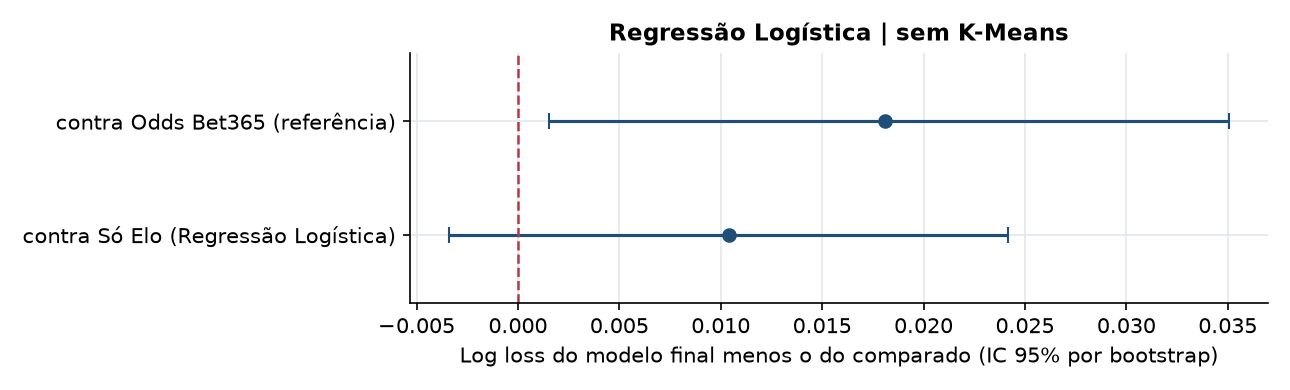

classificacao_calibracao.png


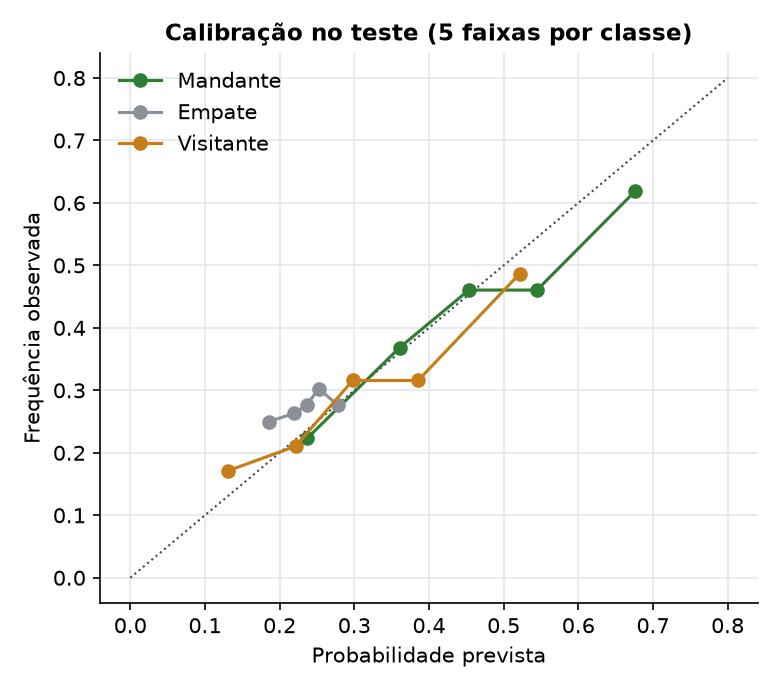

classificacao_log_loss_por_temporada.png


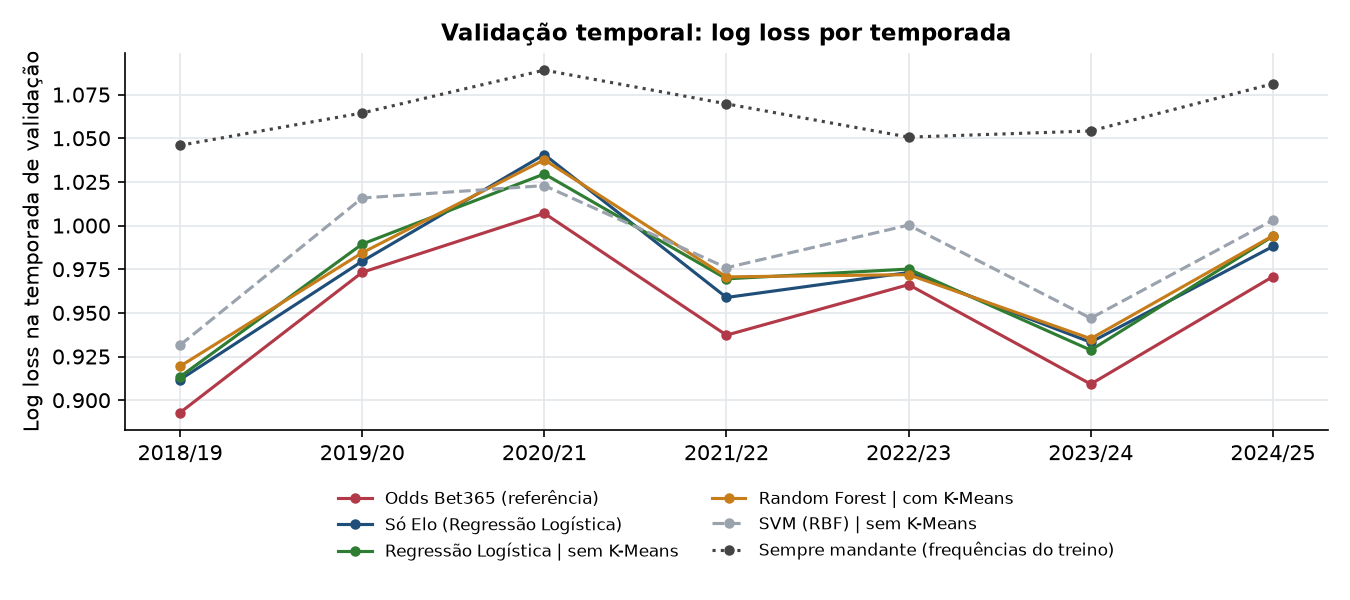

classificacao_log_loss_teste.png


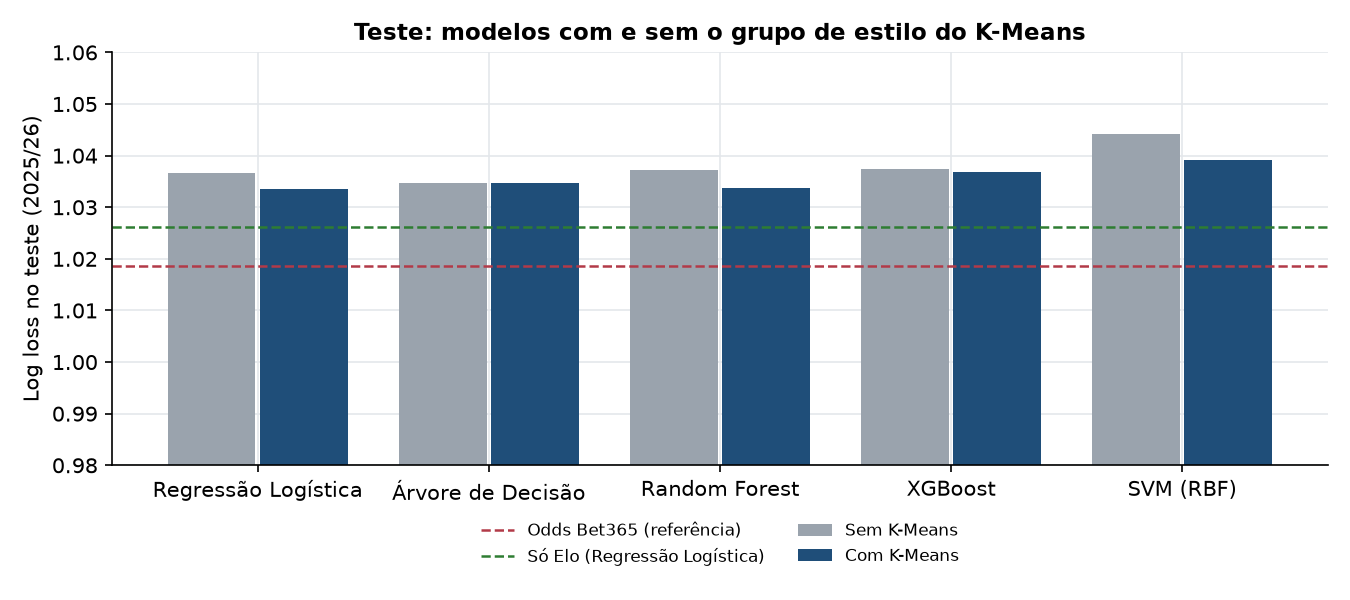

classificacao_matrizes_confusao.png


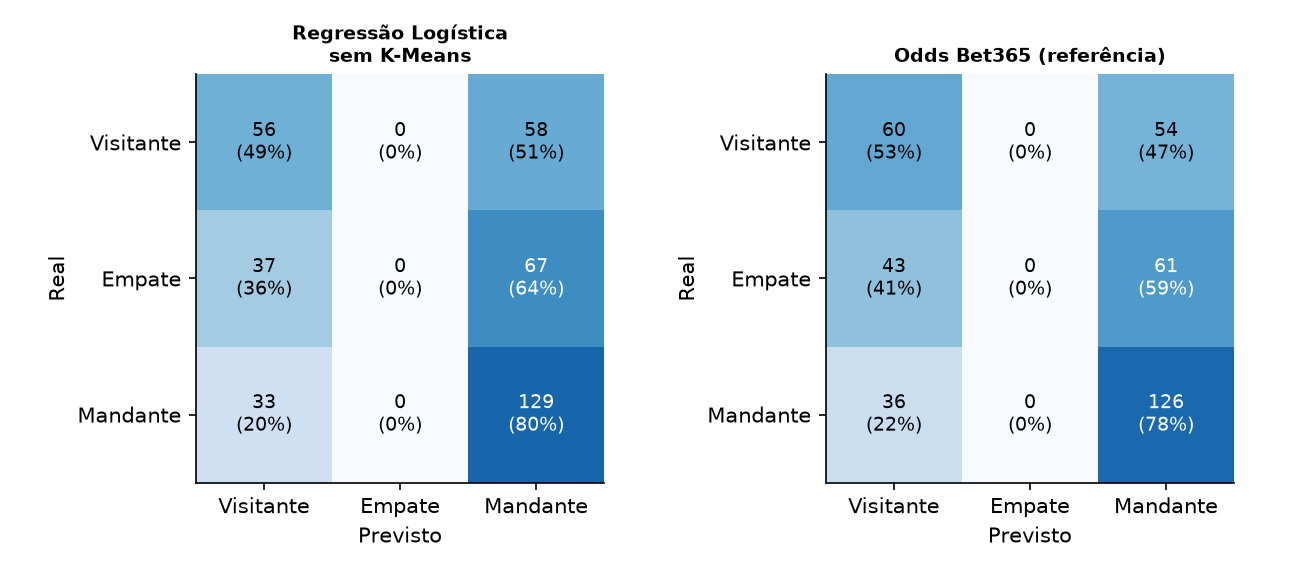

classificacao_roc.png


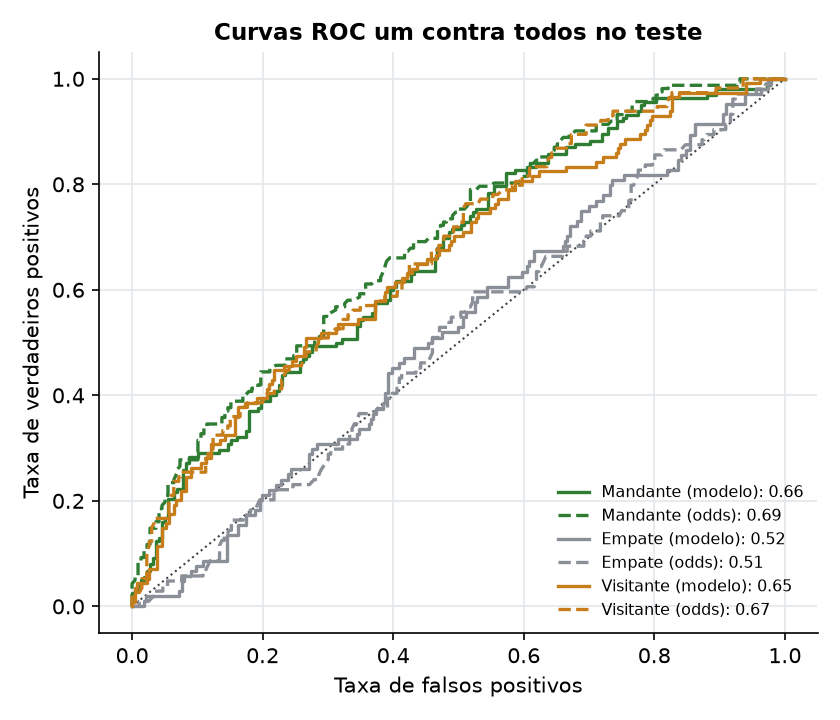

eda_resultados_por_temporada.png


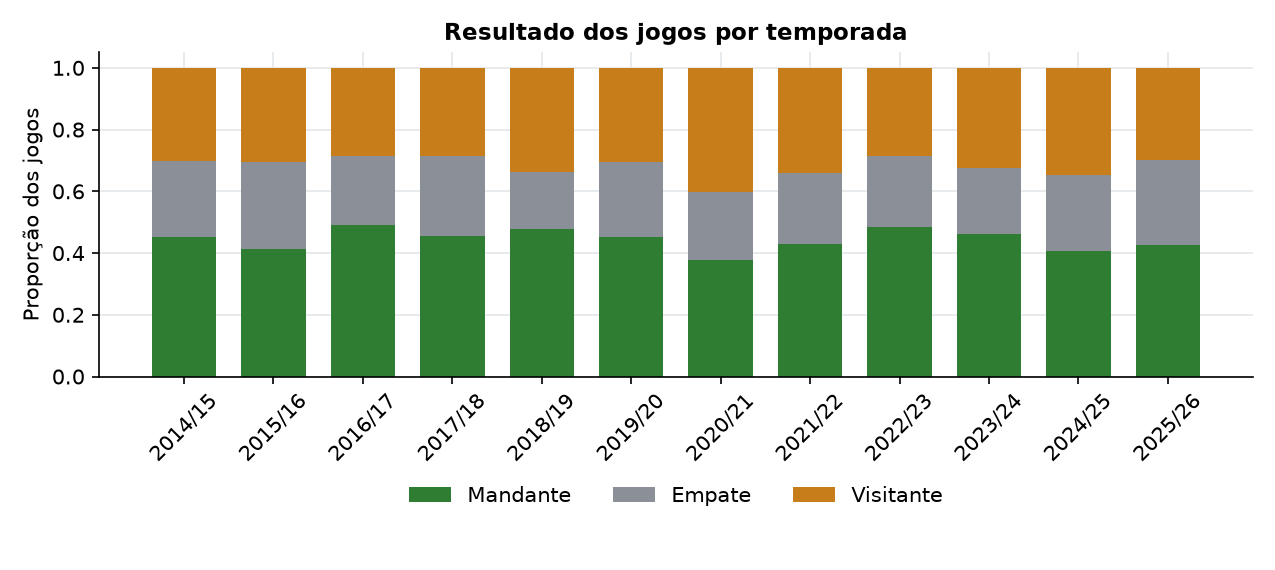

eda_saldo_gols.png


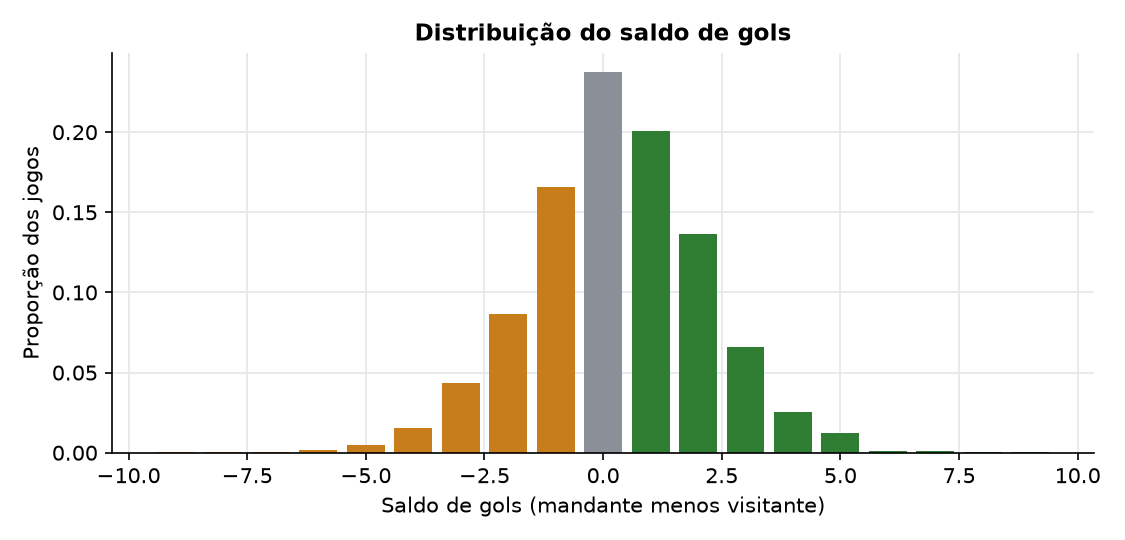

kmeans_perfis.png


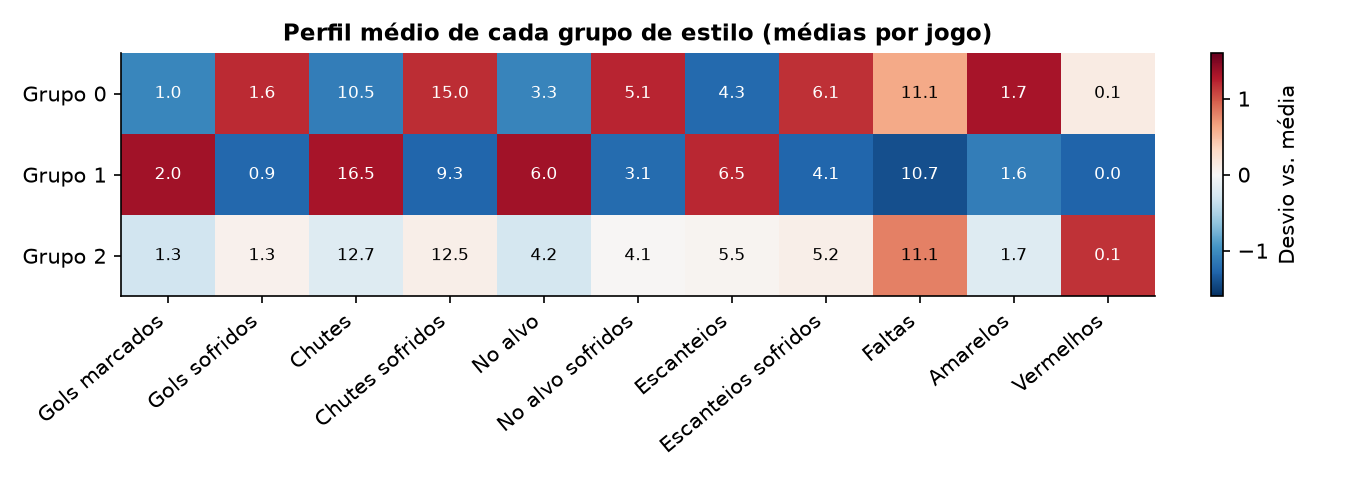

kmeans_selecao_k.png


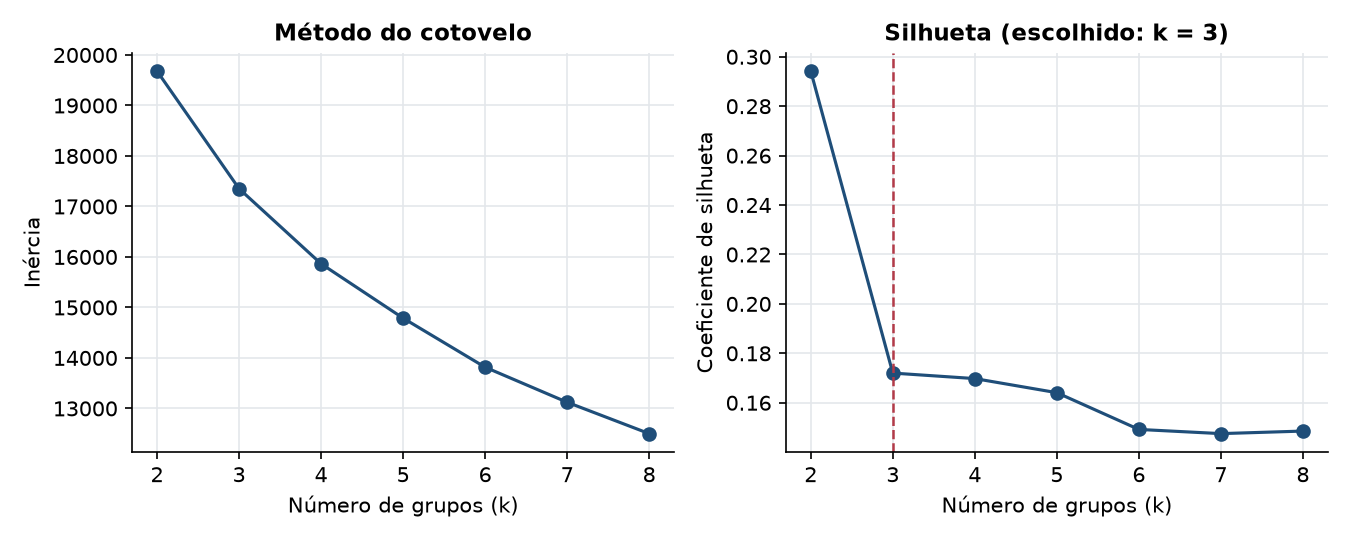

regressao_comparacao.png


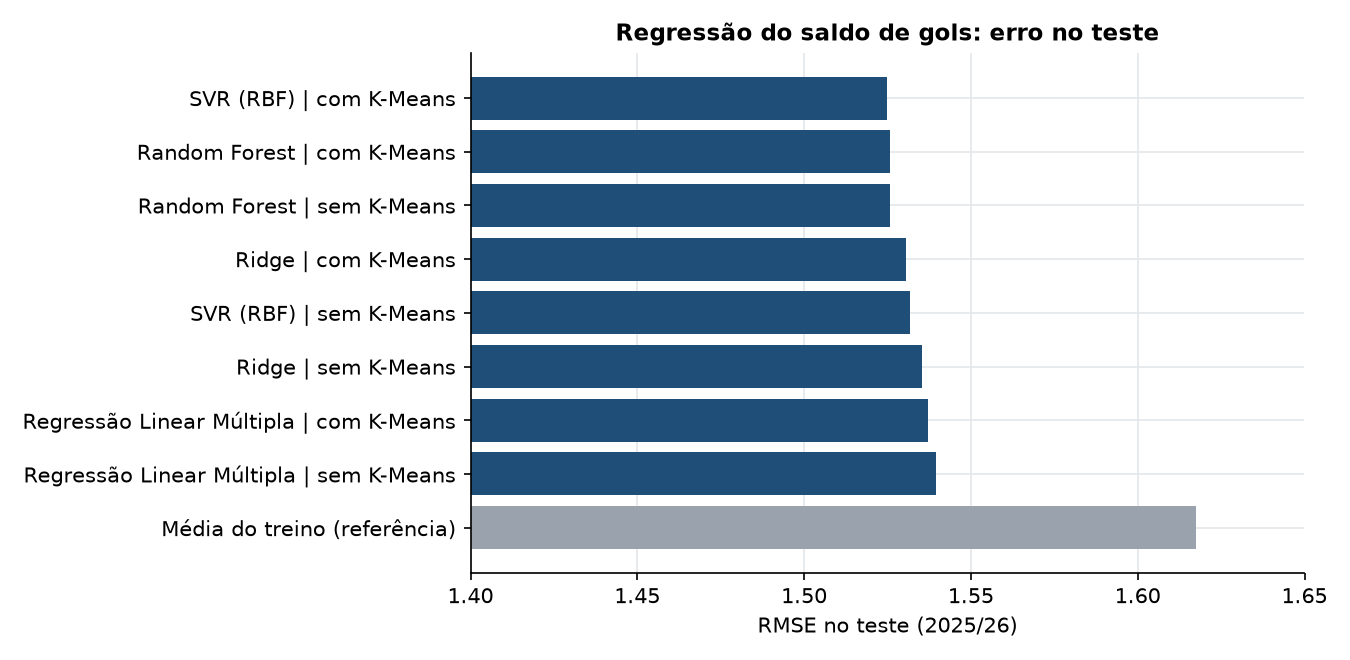

regressao_real_vs_previsto.png


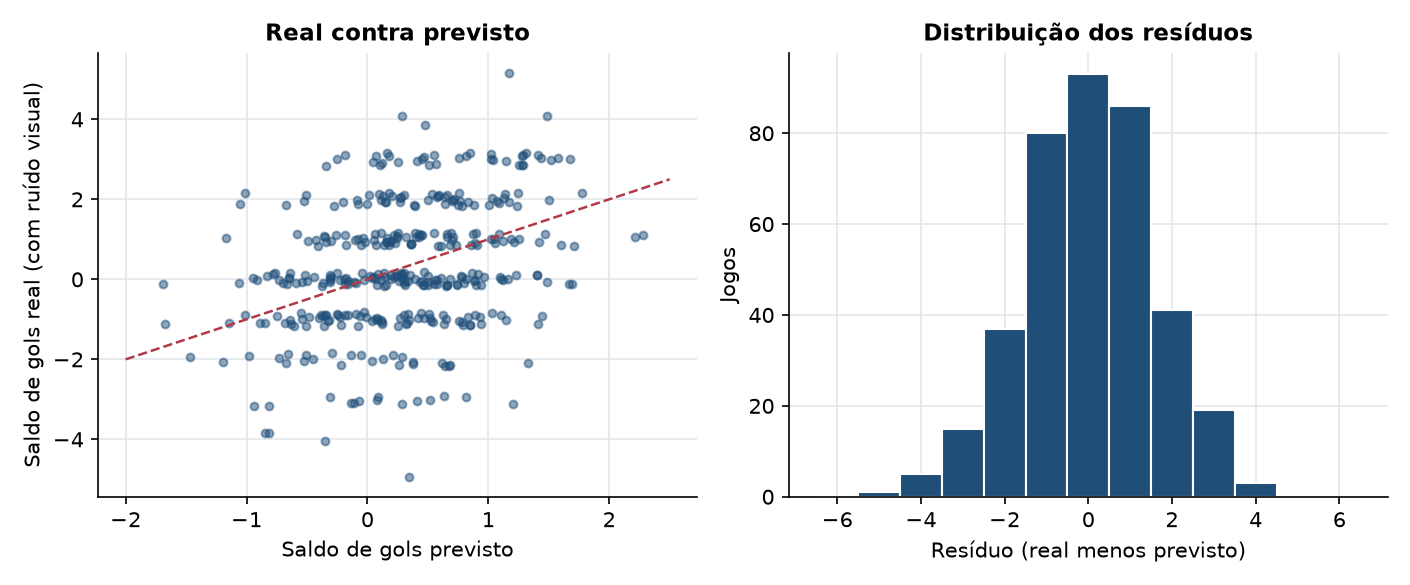

In [14]:
warnings.filterwarnings("ignore")
gerar_todas_as_figuras()
for arquivo in sorted(PASTA_FIGURAS.glob("*.png")):
    print(arquivo.name)
    display(Image(filename=str(arquivo), width=760))

## 8. Conclusões

- **O teto é baixo e a régua é a odd.** Nenhum modelo supera de forma consistente as odds da Bet365 na validação, e o melhor modelo final fica significativamente atrás delas no teste. Prever futebol com dados públicos de jogo tem um limite próximo do que o mercado já embute.
- **Modelos simples ganham.** Na validação em 7 temporadas, o modelo só com Elo empata com a Regressão Logística completa e fica ligeiramente à frente dos ensembles, da árvore e do SVM. Mesmo depois de ampliar as grades duas vezes, os melhores hiperparâmetros ficam nos extremos mais regularizados (C = 0,003 na logística, árvore de profundidade 2, C = 0,01 e gamma = 0,00003 no SVM), sinal de pouco sinal extra nas variáveis. O SVM tende a um modelo quase constante e não ganha nada do kernel.
- **O K-Means não ajudou de forma consistente.** Os grupos de estilo são interpretáveis (defensivos e frágeis, dominantes, equilibrados), mas a diferença de log loss com e sem eles é de no máximo 0,001 na validação, e a Regressão Logística chega a piorar um pouco. No teste todos melhoram ou empatam (até 0,005 no SVM), mas são 380 jogos e a validação em 7 temporadas não confirma o ganho. A silhueta baixa confirma que estilo é um contínuo, não grupos nítidos.
- **Empate quase não se prevê.** Nenhum modelo o escolhe como resultado mais provável, então o recall do empate é zero e o F1 macro fica perto de 0,36. As probabilidades, não o rótulo, são o produto útil.
- **Regressão do saldo de gols:** reduz o erro em relação à média do treino (RMSE perto de 1,53 contra 1,62), mas explica só cerca de 10% da variância.

### Limitações

- O teste tem 380 jogos, então diferenças pequenas entre modelos ficam dentro do erro. A validação em 7 temporadas pesa mais na decisão.
- Só uma liga e dados de jogo. Sem escalação, lesões, xG por partida nem odds de fechamento como variável.
- O Elo e os hiperparâmetros foram definidos com o desenvolvimento, e a temporada 2025/26 só foi usada no fim, mas o desenho do experimento foi pensado já sabendo como o futebol costuma se comportar.
- As odds são só régua de dificuldade. O trabalho não avalia nem recomenda apostas.